In [1]:
import numpy as np
import pandas as pd
import scipy as scp
import matplotlib.pyplot as plt
import matplotlib.cm as cmx
import mne
from mne.datasets import sample
import os.path as op
import os
from tqdm import tqdm
from src.utils import event_shape,init_hmp,GAMMA2,plot_hsmm,event_shape,plot_val_hsmm,sample_hmp,sim1,get_hmp_event_probs
from mssmViz.plot import *
from mssm.models import *
from mssmViz.plot import *
from mssm.src.python.gamm_solvers import gd_coef_smooth,correct_coef_step_gen_smooth
from mssm.src.python.formula import build_model_matrix
from mssm.src.python.hsmm import HSMMFamily
from mssm.src.python.mcmc import sample_mssm
from mssm.src.python.utils import computeAr1Chol
from hmp.io import read_mne_raw
from mssm.src.python.compare import compare_CDL
import hmp
import dotenv
dotenv.load_dotenv()

nc = 10
colors = [cmx.tab20(x) for x in np.linspace(0.0,min(0.1*nc,1.0),nc)]
single_size = 8/2.54

plt.rcParams["font.family"] = "Source Sans 3"
plt.rcParams["font.weight"] = "semibold"
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.titlesize"] = 12
math_font_size = 8
plt.rcParams['mathtext.fontset'] = 'cm'

results_path = os.getenv("results_path")
use_cores = int(os.getenv("n_cores"))

In [2]:
# Code (and comments) below was largely taken from the HMP tutorials available on Github to
# simulate data for a HMP model and to load that data back in. Code has been adapted slightly to
# simulate a non-linear effect of covariate x on the duration of flat states.
# see: https://github.com/GWeindel/hmp/blob/devel/docs/source/notebooks/1-How_HMP_works.ipynb

cpus = 4 # For multiprocessing 

n_trials = 500 #Number of trials to simulate
sfreq = 100

##### Here we define the sources of the brain activity (event) for each trial
n_events = 3
frequency = 10. #Frequency of the event defining its duration, half-sine of 10Hz = 50ms
amplitude = .2e-7 #Amplitude of the event in nAm, defining signal to noise ratio
scale = 0.5 # Scale parameter of Gamma distribution when expressed as member of exponential family

#Which source to activate for each event (see atlas when calling simulations.available_sources())
names = ['inferiortemporal-lh','caudalanteriorcingulate-rh','bankssts-lh','superiorparietal-lh']


In [3]:
# Generate sources
true_durs,x,file = sim1(3,n_trials,names,scale,frequency,amplitude,2025,sfreq,use_cores)

Simulating ./dataset_raw_raw.fif
./dataset_raw_raw.fif simulated


Processing dataset dataset_raw
Opening raw data file dataset_raw_raw.fif...
    Read a total of 1 projection items:
        Average EEG reference (1 x 60) active
    Range : 0 ... 114020 =      0.000 ...  1140.200 secs
Ready.
Reading 0 ... 114020  =      0.000 ...  1140.200 secs...
Adding metadata with 5 columns
500 matching events found
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 500 events and 1021 original time points ...
1 bad epochs dropped
Found 499 trials with positively defined durations and 0 trials without durations (0 or nan)

Rejection summary: 
 0 trials rejected based on threshold of inf 
 0 trials rejected  based on duration limit of (0.01, 10.0) 
 0 with duration but without data (nan at time 0)


/Users/joshmac/Documents/repos/hsmm_mvpy/hmp/patterndata.py:159: UserWarning: Data was not padded, distortion in the crosscorrelation at the edge of the trials is likely. Use the offsets argument in basedata with offsets of at least 3 samples given sampling frequency
  warn("Data was not padded, distortion in the crosscorrelation at the edge of the trials "


Estimating 3 events model


/Users/joshmac/Documents/repos/hsmm_mvpy/hmp/patterndata.py:159: UserWarning: Data was not padded, distortion in the crosscorrelation at the edge of the trials is likely. Use the offsets argument in basedata with offsets of at least 3 samples given sampling frequency
  warn("Data was not padded, distortion in the crosscorrelation at the edge of the trials "


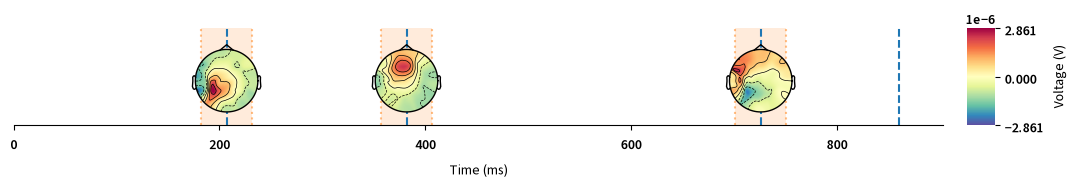

In [4]:
# Epoch data
data_path = sample.data_path()
subjects_dir = op.join(data_path, 'subjects')
subject = 'sample'
evoked_fname = op.join(data_path, 'MEG', subject, 'sample_audvis-ave.fif')
info = mne.io.read_info(evoked_fname, verbose=False)
positions = np.delete(mne.channels.layout._find_topomap_coords(info, 'eeg'),52,axis=0)

# Recovering the events to epoch the data (in the number of trials defined above)
events = np.load(file[1])
resp_trigger = int(np.max(np.unique(events[:,2]))) # Resp trigger is the last source in each trial

# Keeping only stimulus and response triggersfile
centering_id = {'stimulus/dummy':1} # trigger 1 = stimulus
event_id = {'response/dummy':resp_trigger}

recordings = [fil[0] for fil in [file]]
events = [np.load(fil[1]) for fil in [file]]

# Epoch data
epoch_data, info = hmp.io.read_mne_raw(recordings,
                            centering_id=centering_id,
                            event_id=event_id, 
                            events_provided=events,
                            montage = info.get_montage(),
                            preprocessing_kwargs={},
                            epoching_kwargs={"tmin":-.2,"tmax":10.,"baseline":(0,0)}
                            )

hmp_data = hmp.basedata.default(
    epoch_data,
    duration_id='response_time',# If we had defined other events in the events_id we would call something like "Other_event_time"
    min_duration=0, # minimum RT of 200ms
    offsets=0, # adding samples before and after the modelled duration to pad the data for the crosscorrelation
    reject_amplitude=np.inf,# Rejection threshold, reject trial if value higher than abs(threshold)
    n_comp=3, #for speed see later tutorials
)


hmp_model = hmp.models.EventModel(n_events=3,starting_points=10)
hmp_model.locations = np.array([30,60,60,30])
lkh, estimates = hmp_model.fit_transform(hmp_data)
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info)

In [5]:
# Now we get the data into the format required by mssm.

# Set up template
template = event_shape(100,50)
location = np.array([3,6,6,3])

# Prepare data for mssm
pd_dat = hmp_data.data.to_dataframe("pc")
pd_dat["samples"] = pd_dat.index.get_level_values("sample")
pd_dat["component"] = pd_dat.index.get_level_values("component")
pd_dat["epochs"] = pd_dat.index.get_level_values("epoch")
pd_dat = pd_dat.droplevel(["epoch","sample","recording"])
pd_dat = pd_dat.reset_index(drop=True)
pd_dat["component"] = "pc_" + pd_dat["component"].astype(str)

pd_dat = pd_dat.sort_values(['epochs', 'component' ,'samples'], ascending=[True,True,True])
pd_dat = pd_dat.iloc[~pd_dat.isna().any(axis=1).values,:]
pd_dat = pd_dat.reset_index(drop=True)

pd_dat.head()
M = len(np.unique(pd_dat["component"]))

# Get into wide format
dat = pd_dat.iloc[pd_dat["component"].values == "pc_0",:].copy()
dat["pc0"] = dat["pc"].values
dat = dat.drop(columns=["component","pc"])
dat = dat.reset_index(drop=True)

for pc in range(1,M):
    dat[f"pc{pc}"] = pd_dat.loc[pd_dat["component"].values == f"pc_{pc}","pc"].values
    dat[f"tpc{pc}"] = dat[f"pc{pc}"].values

dat["x"] = 5.0
xts = []
rts = []
true_stacked_durs = []
for epoch in np.unique(dat["epochs"]):
    dat.loc[dat["epochs"].values == epoch,"x"] = x[epoch]
    xts.append(x[epoch])
    rts.append(dat.loc[(dat["epochs"].values == epoch),"samples"].max())
    true_stacked_durs.append(true_durs[:,epoch])

print(dat.head())

# Split vector per series/epoch
uval, id = np.unique(np.array(dat["epochs"]),return_index=True)
sid = np.sort(id)
split_series = sid[1:]
true_stacked_durs = np.array(true_stacked_durs)

  event_name  stimulus_time  response_time stimulus response      subject  \
0      dummy            0.0           0.53    dummy    dummy  dataset_raw   
1      dummy            0.0           0.53    dummy    dummy  dataset_raw   
2      dummy            0.0           0.53    dummy    dummy  dataset_raw   
3      dummy            0.0           0.53    dummy    dummy  dataset_raw   
4      dummy            0.0           0.53    dummy    dummy  dataset_raw   

   samples  epochs       pc0       pc1      tpc1       pc2      tpc2         x  
0        0       0 -0.129354 -0.862835 -0.862835  2.882186  2.882186  0.994458  
1        1       0  0.410289 -0.591189 -0.591189  2.318648  2.318648  0.994458  
2        2       0  0.462500 -0.644668 -0.644668  2.046768  2.046768  0.994458  
3        3       0  0.552953  0.243770  0.243770  1.337256  1.337256  0.994458  
4        4       0 -0.118661 -0.126197 -0.126197  2.023833  2.023833  0.994458  


In [6]:

# Set up formulas for constant model
o_family = None # HMP template/bump is assumed observation model
d_family = GAMMA2(links=[LOG()]) # Gamma 2 for stage durations 
n_S = 7
M = 3
D = max(rts)
tid = np.arange(len(xts))

ys = []
Xs = []
form_n_coef = []
init_coef = []
obs_families = []
shared_formulas = []
obs_formulas = []
build_matrix = []
build_mat_idx = []
links = []
pars = 0


ar=False
rho = 0.7
Lrhoi = None

if ar:
    ar_form = Formula(lhs(f"pc{1}"),[i()],data=dat,series_id="epochs")
    Lrhoi,_ = computeAr1Chol(ar_form,rho)

# Emission models
event = 0
start_sep = len(build_matrix)
for j in range(n_S):
    obs_families.append([])

    for m in range(M):

        obs_families[-1].append(o_family)

        if j % 2 == 1:
            
            # Model of mean of obs model in state j and of signal m
            obs_formulas.append(Formula(lhs(f"pc{m}"),[i()],data=dat))

            init_coef.extend(scp.stats.norm.rvs(size=obs_formulas[-1].n_coef,
                                                random_state=event*(m+1) + m))
            form_n_coef.append(obs_formulas[-1].n_coef)
            _ = build_penalties(obs_formulas[-1])
            ys.append(dat[f"pc{m}"].values.reshape(-1,1))

            if len(build_matrix) == start_sep:
                build_matrix.append(True)
                Xs.append(build_model_matrix(obs_formulas[-1]))
            else:
                build_matrix.append(False)
                Xs.append(None)
            build_mat_idx.append(start_sep)
        
            links.extend([Identity()])
            if m >= (M-1):
                event += 1
            pars += 1


# Duration models
d_dat = pd.DataFrame({"x":xts,
                      "d":np.arange(len(xts)),
                      "sub":np.ones(len(xts))})

d_dat = d_dat.astype({"sub":"O"})

d_families = []
d_formulas = []

flat = 0
start_durs = len(build_mat_idx)
for j in range(n_S):

    if j % 2 == 1:
        d_families.append(None)
    else:

        d_families.append(d_family)

        # Model of mean of dur model in state j
        d_formulas.append(Formula(lhs("d"),[i()],data=d_dat)) 
        if flat == 0:
            build_matrix.append(True)
            _ = build_penalties(d_formulas[-1])
            Xs.append(build_model_matrix(d_formulas[-1]))
        else:
            build_matrix.append(False)
            Xs.append(None)
        
        build_mat_idx.append(start_durs)
        form_n_coef.append(d_formulas[-1].n_coef)
        init_coef.extend([5])
        ys.append(d_dat["d"].values.reshape(-1,1))

        links.extend(d_family.links)
        flat += 1
        pars += 1

# Initialize Family
T = np.diag(
    np.ones(n_S - 1), 1
)  # Super diagonal shift matrix for transitions

pi = np.zeros(n_S)  # Start in first state
pi[0] = 1

fam = HSMMFamily(pars,
                links,
                n_S,
                obs_fams=obs_families,
                d_fams=d_families,
                sid = sid,
                tid = tid,
                D = D,
                M = M,
                starts_with_first=True,
                ends_with_last=True,
                ends_in_last=True,
                T=T,
                pi=pi,
                scale = 2,
                event_template=template,
                hmp_fam="Gaussian",
                n_cores=1,
                build_mat_idx=build_mat_idx,
                Lrhoi=Lrhoi,
                hmp_location=location,
                fast_hmp=False,
                hmp_d_offset=True)

# Initialize coef
coef_split_idx = form_n_coef[:-1]

for coef_i in range(1,len(coef_split_idx)):
    coef_split_idx[coef_i] += coef_split_idx[coef_i-1]

total_coef = np.sum(form_n_coef)
init_coef = np.array(init_coef).reshape(-1,1)

# Set up pseudo-penalty that is all zero
S_emb = scp.sparse.csc_array((total_coef,total_coef))

fam.prefit_setup(ys,Xs)


In [7]:
# Fit model with mssm
model = GSMM([*obs_formulas,*d_formulas],fam)
model.fit(init_coef=init_coef,n_cores=1,
          build_mat=build_matrix,repara=False,
          prefit_grad=False,method='qEFS',
          sample_hessian=False,structured_qefs=False,global_opt_qefs=False,
          qEFS_final_memory_usage=1,sample_hessian_options={"init_r":1e-3,"adapt_r":False})
coef = model.coef

In [ ]:
# Plot the residuals of the HMP - they generally look fine. The auto-correlation can
# largely be adressed by setting ar = True in the model specification above.
# However, we know that the model of the expected flat state durations is wrong in this case -
# but as mentioned in the paper, this really does not show up in the forward pseudo residuals.
fig = plt.figure(figsize=(19 / 2.54, 6 / 2.54), layout="constrained")

plot_val_hsmm(model,model.get_ys(),dat,d_dat,0,
              per_component=False,
              seed=1,predictive_examples=500,
              quantile_label_pos=0.65,wspace=0.01,fig=fig,n_samples=100,
              select_component=0
             )

plt.savefig(results_path + f"resid_overview{'_ar' if ar is True else ''}.png", format="png", bbox_inches='tight',dpi=300)
plt.show()

In [ ]:
# Let's try the "correct" smooth model instead.
# Set up formulas
ys = []
Xs = []
form_n_coef = []
obs_families = []
obs_formulas = []
build_mat_idx = []
build_matrix = []
links = []
pars = 0

# Emission models

event = 0
start_sep = 0
for j in range(n_S):
    obs_families.append([])

    for m in range(M):

        obs_families[-1].append(o_family)

        if j % 2 == 1:
            
            # Model of mean of obs model in state j and of signal m
            obs_formulas.append(Formula(lhs(f"pc{m}"),[i()],data=dat))
            form_n_coef.append(obs_formulas[-1].n_coef)
            _ = build_penalties(obs_formulas[-1])
            ys.append(dat[f"pc{m}"].values.reshape(-1,1))

            if len(build_matrix) == start_sep:
                build_matrix.append(True)
                Xs.append(build_model_matrix(obs_formulas[-1]))
            else:
                build_matrix.append(False)
                Xs.append(None)
            build_mat_idx.append(start_sep)

            links.extend([Identity()])
            if m >= (M-1):
                event += 1
            pars += 1

# Duration models

d_dat = pd.DataFrame({"x":xts,
                      "d":np.arange(len(xts))})

d_families = []
d_formulas = []

flat = 0
start_d = len(build_mat_idx)
for j in range(n_S):

    if j % 2 == 1:
        d_families.append(None)
    else:

        d_families.append(d_family)

        # Model of mean of dur model in state j - now includes a function of covariate x
        d_formulas.append(Formula(lhs("d"),[i(),f(["x"])],data=d_dat)) 

        if flat == 0:
            build_matrix.append(True)
            _ = build_penalties(d_formulas[-1])
            Xs.append(build_model_matrix(d_formulas[-1]))
        else:
            build_matrix.append(False)
            Xs.append(None)
        
        build_mat_idx.append(start_d)
        form_n_coef.append(d_formulas[-1].n_coef)
        ys.append(d_dat["d"].values.reshape(-1,1))


        links.extend(d_family.links)
        flat += 1
        pars += 1

# Initialize Family
fam2 = HSMMFamily(pars,
                  links,
                  n_S,
                  obs_fams=obs_families,
                  d_fams=d_families,
                  sid = sid,
                  tid = tid,
                  D = D,
                  M = M,
                  starts_with_first=True,
                  ends_with_last=True,
                  ends_in_last=True,
                  T=T,
                  pi=pi,
                  scale = 1,
                  event_template=template,
                  hmp_fam="Gaussian",
                  n_cores=1,
                  n_cores_llk=1,
                  build_mat_idx=build_mat_idx,
                  Lrhoi=Lrhoi,
                  hmp_location=location,
                  fast_hmp=True,)

coef_split_idx = form_n_coef[:-1]

for coef_i in range(1,len(coef_split_idx)):
    coef_split_idx[coef_i] += coef_split_idx[coef_i-1]

total_coef = np.sum(form_n_coef)
fam2.prefit_setup(ys,Xs)

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont: Failed to find font weight semibold, now using 400.
findfont

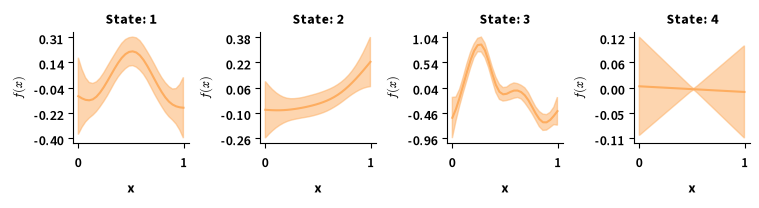

In [ ]:
# Initialize from viterbi for cheap fitting.
viterbi = fam.decode_viterbi(model.coef,model.coef_split_idx,model.get_ys(),model.get_mmat())
fig = plt.figure(figsize=(19 / 2.54, 5 / 2.54), layout="constrained")
axs = fig.subplots(1, 4, gridspec_kw=dict(wspace=0.01,hspace=0.01))
init_coef, init_lambda = init_hmp(dat,d_dat,obs_formulas,d_formulas,
                                  [viterbi[s][1] for s in range(len(viterbi))],
                                  fam2,Xs,ys,True,None,should_plot=True,axs=axs)

axs = fig.get_axes()
states = [0,2,4,6]
for axi in range(len(axs)):
    axs[axi].set_title(f"State: {states[axi]//2 + 1}",fontweight="bold")
plt.show()

In [10]:
model2 = GSMM([*obs_formulas,*d_formulas],fam2)
model2.fit(init_coef=init_coef,init_lambda=init_lambda,
           n_cores=1,build_mat=build_matrix,repara=False,
           prefit_grad=False,method='qEFS',sample_hessian=True,
           structured_qefs=False,global_opt_qefs=False,max_restarts=-1)
coef2 = model2.coef

Converged!:   2%|▏         | 4/200 [22:15<18:10:41, 333.88s/it]                


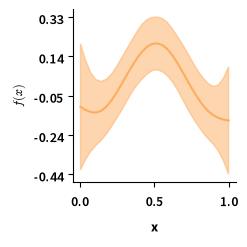

In [11]:
plot(model2,dist_par=9)

In [12]:
mssm_estimates = estimates.copy()
ev_probs = get_hmp_event_probs(fam2,model2.coef,model2.coef_split_idx,model2.get_ys(),model2.get_mmat())
mssm_estimates.data = ev_probs

split_coef = np.split(model2.coef,model2.coef_split_idx)
b_coef = np.array([split_coef[j][0] for j in range(event*M)]).reshape(-1,1)

topographies = np.zeros((59,1,3))
for evidx in range(3):
    magnitudes = b_coef[evidx*M:(evidx+1)*M]
    topographies[:,0,evidx] = np.ndarray.flatten(magnitudes.T @ hmp_data.projector.weights.data.T)

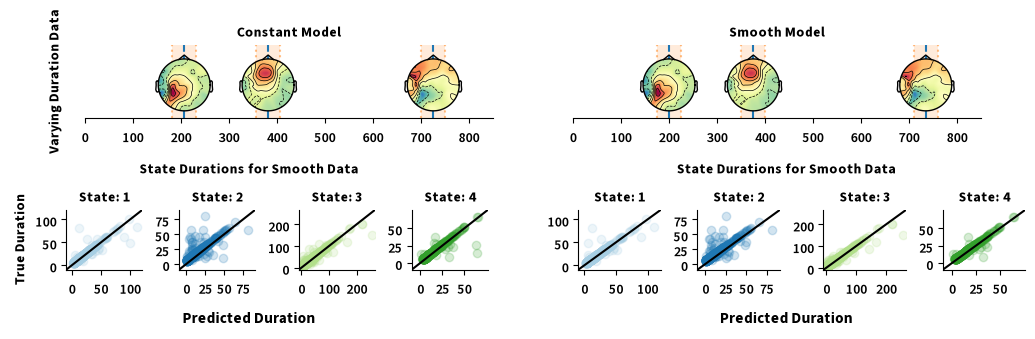

In [13]:
fig = plt.figure(figsize=(26 / 2.54, 8 / 2.54), layout="constrained")
sub_figs = fig.subfigures(2, 1,height_ratios=[0.75, 1])
cmp = matplotlib.colormaps["Paired"]
states = [0,2,4,6]
mssm_models = [model,model2]
axs1 = sub_figs[0].subplot_mosaic([[".","a","b","."]],
                                   gridspec_kw=dict(wspace=0.3,
                                                    hspace=0.05,
                                                    width_ratios=[1e-6,1,1,0.025]))

hmp.visu.plot_topo_timecourse(epoch_data, estimates, info,
                           ax=axs1["a"],magnify=2.25,colorbar=False)
hmp.visu.plot_topo_timecourse(epoch_data, mssm_estimates, info,
                           topographies=None,ax=axs1["b"],magnify=2.25,colorbar=False)


for axk in axs1.keys():
    axs1[axk].spines['top'].set_visible(False)
    axs1[axk].spines['right'].set_visible(False)
    axs1[axk].set_xlim((0,850))
    axs1[axk].set_xticks(np.arange(0,850,100))

axs1["a"].set_title("Constant Model",
                    fontsize= plt.rcParams['axes.titlesize'],
                    fontweight= "bold",family="Source Sans 3")
axs1["b"].set_title("Smooth Model",
                    fontsize= plt.rcParams['axes.titlesize'],
                    fontweight= "bold",family="Source Sans 3")
axs1["a"].set_ylabel("Varying Duration Data",
                    fontsize= plt.rcParams['axes.labelsize'],
                    fontweight= "bold",family="Source Sans 3",labelpad=15)

sub_figs_nested = sub_figs[1].subfigures(1,2,wspace=0.1)

viterbi1 = mssm_models[0].family.decode_viterbi(mssm_models[0].coef,
                                                mssm_models[0].coef_split_idx,
                                                mssm_models[0].get_ys(),
                                                mssm_models[0].get_mmat())
viterbi2 = mssm_models[1].family.decode_viterbi(mssm_models[1].coef,
                                                mssm_models[1].coef_split_idx,
                                                mssm_models[1].get_ys(),
                                                mssm_models[1].get_mmat())

dur_ests1 = np.zeros_like(true_stacked_durs)
dur_ests2 = np.zeros_like(true_stacked_durs)

for event in range(len(viterbi1)):
    
    fi = 0
    for state in range(n_S):
        if state % 2 == 0:
            dur_ests1[event,fi] = np.sum(viterbi1[event][1] == state)
            dur_ests2[event,fi] = np.sum(viterbi2[event][1] == state)
            fi += 1

for midx in range(2):
    if midx == 0:
        dur_ests = dur_ests1
    else:
        dur_ests = dur_ests2

    sub_figs_nested[midx].suptitle("State Durations for Smooth Data",
                fontsize= plt.rcParams['axes.titlesize'],
                fontweight= "bold",family="Source Sans 3")


    axs = sub_figs_nested[midx].subplots(1, 4, gridspec_kw=dict(wspace=0.05))

    for fi in range(n_events+1):
        maxD = max(np.max(dur_ests[:,fi]),
                np.max(true_stacked_durs[:,fi]/10))
        axs[fi].set_xlim((-10,maxD+10))
        axs[fi].set_ylim((-10,maxD+10))
        ticks = np.arange(0,maxD,25 if maxD < 100 else (50 if maxD < 200 else 100))
        axs[fi].set_xticks(ticks)
        axs[fi].set_yticks(ticks)
        
        line_ticks = ticks.copy()
        line_ticks[-1] = maxD+10
        line_ticks[0] = -10
        axs[fi].plot(line_ticks,line_ticks,color='black')

        
        axs[fi].scatter(dur_ests[:,fi],true_stacked_durs[:,fi]/10,color=cmp(states[fi]//2),alpha=0.2)
        axs[fi].spines["top"].set_visible(False)
        axs[fi].spines["right"].set_visible(False)
        axs[fi].set_title(
            f"{'State'}: {(states[fi] // 2) + 1}",
            fontweight="bold",
        )
        if fi == 0 and midx == 0:
            axs[fi].set_ylabel("True Duration",fontweight="bold")
    sub_figs_nested[midx].supxlabel("Predicted Duration",fontweight="bold")


plt.savefig(results_path + "smooth_dur_sim.pdf", format="pdf", bbox_inches='tight')
plt.savefig(results_path + "smooth_dur_sim.png", format="png", bbox_inches='tight',dpi=300)
plt.show()

In [ ]:
# In terms of state decoding and topographies recovered, both models look pretty much identical.
# That is because the Gamma of the constant model (model) can always become wider to accomodate
# fluctuations in the mean. But model2 is still much better in terms of aic
test = compare_CDL(model2,model,grid="JJJ1")
print(test["aic_diff"])

In [ ]:
# As an alternative we look at the average durations as defined in the paper - these do show that
# the residuals of model depend strongly on covariate x - and, for flat states 1 and 3, we can
# actually recover the true function of x quite accurately from the residuals.
# model2 fixes this.
fig = plt.figure(figsize=(19 / 2.54, 10 / 2.54), layout="constrained")
sub_figs = fig.subfigures(2, 1,hspace=0.1)

plot_val_hsmm(model,model.get_ys(),dat,d_dat,3,
              per_component=False,fig=sub_figs[0],
              seed=2,predictive_examples=5,
              quantile_label_pos=0.6,wspace=0.01,
              pred_vars=["x"],resid_states=[0,2,4,6],
              n_samples=100,resid_terms=[i(),f(["x"])],
              type_3_res="posterior_dur",hspace=0.05,plot_partial=None)

sub_figs[0].suptitle("Average Duration Residuals for Constant Model",
                    fontsize= plt.rcParams['axes.titlesize'],
                    fontweight= "bold",family="Source Sans 3")

plot_val_hsmm(model2,model2.get_ys(),dat,d_dat,3,
              per_component=False,fig=sub_figs[1],
              seed=2,predictive_examples=5,
              quantile_label_pos=0.6,wspace=0.01,
              pred_vars=["x"],resid_states=[0,2,4,6],
              n_samples=100,resid_terms=[i(),f(["x"])],
              type_3_res="posterior_dur",hspace=0.05,plot_partial=None)

sub_figs[1].suptitle("Average Duration Residuals for Smooth Model",
                    fontsize= plt.rcParams['axes.titlesize'],
                    fontweight= "bold",family="Source Sans 3",y=1.1)


sub_figs[0].axes[0].set_xlabel("")
sub_figs[0].axes[1].set_xlabel("")
sub_figs[0].axes[2].set_xlabel("")
sub_figs[0].axes[3].set_xlabel("")
sub_figs[0].axes[0].set_title("State 1")
sub_figs[0].axes[1].set_title("State 2")
sub_figs[0].axes[2].set_title("State 3")
sub_figs[0].axes[3].set_title("State 4")
sub_figs[1].axes[0].set_title("")
sub_figs[1].axes[1].set_title("")
sub_figs[1].axes[2].set_title("")
sub_figs[1].axes[3].set_title("")


plt.savefig(results_path + "smooth_dur_sim_resid.pdf", format="pdf", bbox_inches='tight')
plt.savefig(results_path + "smooth_dur_sim_resid.png", format="png", bbox_inches='tight',dpi=300)
plt.show()